In [24]:
import requests 
import pandas as pd 
import datetime


In [25]:
api_key = 'fb365aa6104829b44455572365ff3b4e' 

In [26]:
lat = 18.184135
lon = 74.610764

In [27]:
api_url = f"http://api.openweathermap.org/data/2.5/forecast?lat={lat}&lon={lon}&appid={api_key}"

In [28]:
response = requests.get(api_url)
weather_data = response.json()
weather_data.keys()
len(weather_data['list'])
weather_data['list'][0]['weather'][0]['description']

'overcast clouds'

In [29]:
temperatures = [item['main']['temp'] for item in weather_data['list']] 

timestamps = [pd.to_datetime(item['dt'], unit='s') for item in weather_data['list']]
temperature = [item['main']['temp'] for item in weather_data['list']]
humidity = [item['main']['humidity'] for item in weather_data['list']]
wind_speed = [item['wind']['speed'] for item in weather_data['list']]
weather_description = [item['weather'][0]['description'] for item in weather_data['list']]

In [30]:
weather_df = pd.DataFrame({'Timestamp': timestamps, 
                           'Temperature': temperatures, 
                           'humidity': humidity, 
                           'wind_speed':wind_speed,
                           'weather_description': weather_description})

In [31]:
weather_df.set_index('Timestamp', inplace=True)
max_temp = weather_df['Temperature'].max()
print(f"Maximum Temperature - {max_temp}")
min_temp = weather_df['Temperature'].min()
print(f"Minimum Temperature - {min_temp}")

Maximum Temperature - 305.16
Minimum Temperature - 294.55


In [32]:
weather_df.fillna(0, inplace=True)

In [33]:
weather_df['Temperature'] = weather_df['Temperature'].apply(lambda x: x - 273.15 if isinstance(x, float)else x)

In [34]:
print(weather_df)

                     Temperature  humidity  wind_speed weather_description
Timestamp                                                                 
2026-10-28 12:00:00        29.08        43        5.21     overcast clouds
2026-10-28 15:00:00        28.74        47        4.94     overcast clouds
2026-10-28 18:00:00        26.55        60        3.85          light rain
2026-10-28 21:00:00        23.21        75        3.12     overcast clouds
2026-10-29 00:00:00        21.94        76        0.22       broken clouds
2026-10-29 03:00:00        24.06        69        1.55     overcast clouds
2026-10-29 06:00:00        29.02        50        1.66       broken clouds
2026-10-29 09:00:00        30.57        39        3.19    scattered clouds
2026-10-29 12:00:00        26.89        54        7.77       broken clouds
2026-10-29 15:00:00        24.97        71        4.93          light rain
2026-10-29 18:00:00        24.00        72        4.42          light rain
2026-10-29 21:00:00      

In [39]:
import matplotlib.pyplot as plt

daily_mean_temp = weather_df['Temperature'].resample('D').mean()

daily_mean_humidity = weather_df['humidity'].resample('D').mean()

daily_mean_wind_speed = weather_df['wind_speed'].resample('D').mean()

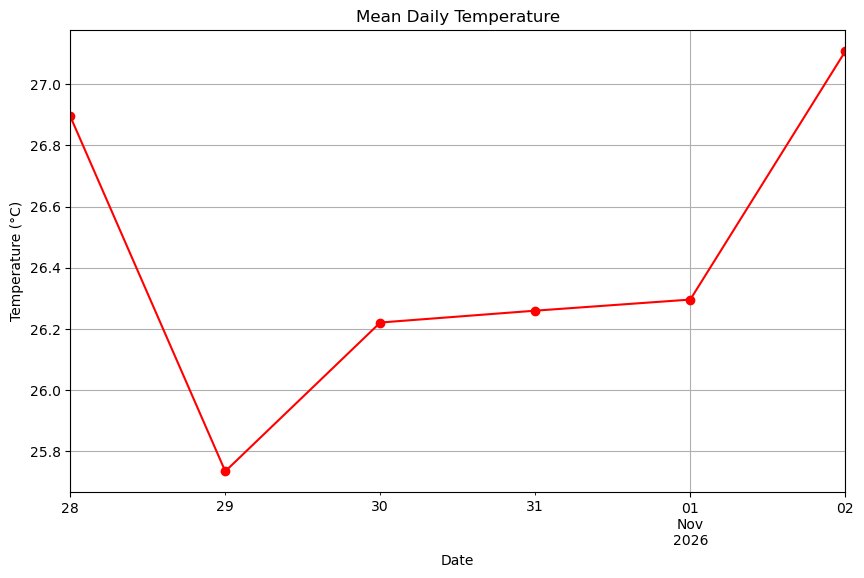

In [40]:
plt.figure(figsize=(10, 6))

daily_mean_temp.plot(color='red', linestyle='-', marker='o')

plt.title('Mean Daily Temperature')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.grid(True)
plt.show()

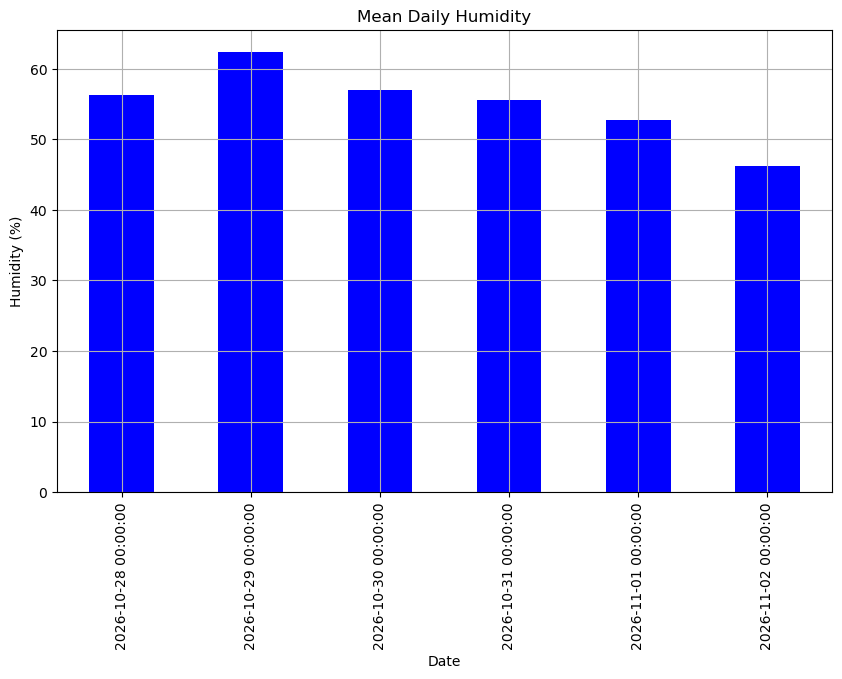

In [41]:
plt.figure(figsize=(10, 6))

daily_mean_humidity.plot(kind='bar', color='blue')

plt.title('Mean Daily Humidity')
plt.xlabel('Date')
plt.ylabel('Humidity (%)')
plt.grid(True)
plt.show()

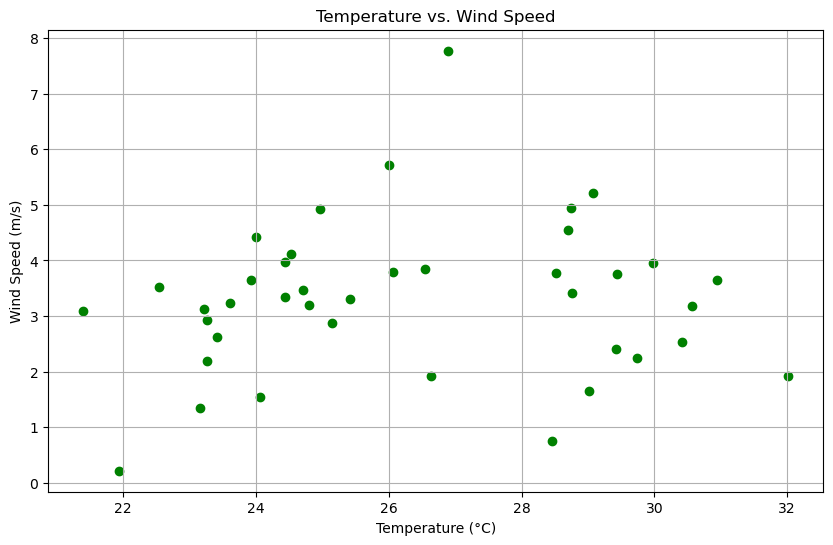

In [42]:
#Scatter plot: Temperature vs. wind speed
plt.figure(figsize=(10, 6))

plt.scatter(
    weather_df['Temperature'],
    weather_df['wind_speed'],
    color='green'
)

plt.title('Temperature vs. Wind Speed')
plt.xlabel('Temperature (°C)')
plt.ylabel('Wind Speed (m/s)')
plt.grid(True)
plt.show()

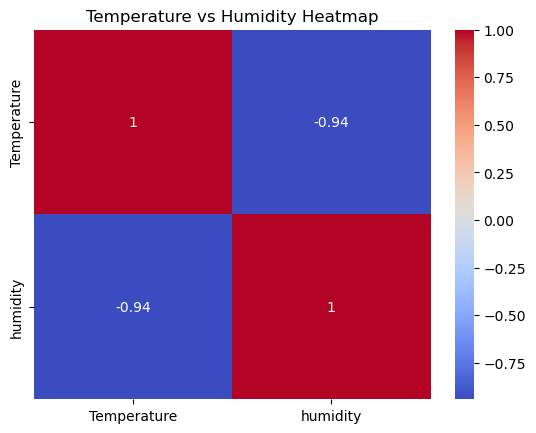

In [43]:
import seaborn as sns

heatmap_data = weather_df[['Temperature', 'humidity']]

sns.heatmap(
    heatmap_data.corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Temperature vs Humidity Heatmap')
plt.show()